In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 100); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("../data")

# ---- knobs ---------------------------------------------------------------
AVAIL_DEF      = "durability"   # "durability" or "usage"
THRESHOLD      = 0.80           # available if rate >= THRESHOLD
REGULAR_SNAPS  = 30             # a game with this many snaps = he's a regular
MIN_GAMES_DEN  = 4              # need at least this many team games in the denominator
MIN_N_GROUP    = 5              # skip a comparison if either group has fewer players
N_BOOT         = 2000
RNG            = np.random.default_rng(27)
GROUP_COLORS   = {"available": "#4C72B0", "not available": "#C44E52"}
# --------------------------------------------------------------------------

SEASONS = [2023, 2024, 2025]; LAST_SEASON = max(SEASONS)
NULLS = ["NA", "NULL", "null", "None", ""]

def find_csv(stem):
    hits = sorted(DATA_DIR.rglob(f"{stem}.csv"))
    if not hits: raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return hits[0]

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

def to_bool(s):
    return s if s.dtype == bool else s.astype(str).str.lower().isin(["true", "1", "y", "yes"])

In [4]:
players = pd.read_csv(find_csv("players"), na_values=NULLS)
combine = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
career  = pd.read_csv(find_csv("player_career_successes"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

prof = (players.merge(combine.drop(columns=[c for c in combine if c in players and c != "nfl_id"]), on="nfl_id", how="left")
               .merge(career.drop(columns=[c for c in career if c in players and c != "nfl_id"]), on="nfl_id", how="left"))

NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
if NAME is None and {"first_name", "last_name"} <= set(prof):
    prof["display_name"] = prof["first_name"] + " " + prof["last_name"]; NAME = "display_name"
NFL_POS, CMB_POS = pick(prof, ["nfl_position", "position"]), pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
ROUND = pick(prof, ["draft_round"])
PICK  = pick(prof, ["draft_pick", "draft_overall_pick", "overall_pick", "draft_number"])
CONF  = pick(prof, ["college_conference", "conference"])
BDAY  = pick(prof, ["birth_date", "birthdate", "dob"])
LUP   = pick(pp, ["lined_up_position", "position_at_snap"], required=True)
TEAM  = pick(pp, ["team_abbr", "club", "team"], required=True)

OL_LABELS = {"OL", "OT", "OG", "IOL", "C", "G", "T", "LT", "RT", "LG", "RG", "OC"}
def to_group(p):
    if pd.isna(p): return np.nan
    p = str(p).upper().strip()
    if p in {"C", "OC"}: return "C"
    if p in {"G", "OG", "LG", "RG"}: return "G"
    if p in {"T", "OT", "LT", "RT"}: return "T"
    return np.nan

is_ol = pd.Series(False, index=prof.index)
for c in [CMB_POS, NFL_POS]:
    if c: is_ol |= prof[c].astype(str).str.upper().isin(OL_LABELS)
ol = prof[is_ol].copy()
ol["listed_group"] = ol[NFL_POS].map(to_group) if NFL_POS else np.nan
if CMB_POS: ol["listed_group"] = ol["listed_group"].fillna(ol[CMB_POS].map(to_group))

gcols = ["game_id", "season", "week"] + [c for c in ["season_type"] if c in games]
ol_pp = pp[pp["nfl_id"].isin(ol["nfl_id"])].merge(games[gcols], on="game_id", how="left")
if "season_type" in ol_pp: ol_pp = ol_pp[ol_pp["season_type"].fillna("REG") == "REG"]
ol_pp["lup_group"] = ol_pp[LUP].map(to_group)

share = ol_pp.dropna(subset=["lup_group"]).groupby(["nfl_id", "lup_group"]).size().unstack(fill_value=0)
for g in "CGT":
    if g not in share: share[g] = 0
share["snaps_at_ol"] = share[list("CGT")].sum(axis=1)
share["played_group"] = share[list("CGT")].idxmax(axis=1)
ol = ol.merge(share[["snaps_at_ol", "played_group"]], left_on="nfl_id", right_index=True, how="left")
ol["snaps_at_ol"] = ol["snaps_at_ol"].fillna(0)
ol["pos_group"] = np.where(ol["snaps_at_ol"] >= 50, ol["played_group"], ol["listed_group"])
ol["interior"] = ol["pos_group"].map({"C": "interior", "G": "interior", "T": "tackle"})

# Derived bio fields
ol["is_udfa"] = ol[ROUND].isna() if ROUND else np.nan
if BDAY:
    combine_day = pd.to_datetime(ol[DRAFT_YR].astype(int).astype(str) + "-03-01")
    ol["age_at_combine"] = (combine_day - pd.to_datetime(ol[BDAY], errors="coerce")).dt.days / 365.25
H, W = pick(ol, ["combine_height", "height"]), pick(ol, ["combine_weight", "weight"])
if H and W: ol["bmi"] = 703 * ol[W] / ol[H] ** 2
print(f"{len(ol)} OL | pos_group:", ol["pos_group"].value_counts(dropna=False).to_dict())

121 OL | pos_group: {'G': 53, 'T': 49, 'C': 19}


In [ ]:
home, away = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])
sched = pd.concat([games[["game_id", "season", "week", home]].rename(columns={home: "team"}),
                   games[["game_id", "season", "week", away]].rename(columns={away: "team"})])
if "season_type" in games:
    sched = sched[sched["game_id"].isin(games.loc[games["season_type"] == "REG", "game_id"])]

pg = ol_pp.groupby(["nfl_id", "season", "week", "game_id"]).agg(snaps=("play_id", "size"), team=(TEAM, "first")).reset_index()
pteam = pg.groupby(["nfl_id", "season"])["team"].agg(lambda s: s.mode().iloc[0]).rename("team").reset_index()

full = (pteam.merge(sched, on=["season", "team"], how="left")
             .merge(pg[["nfl_id", "game_id", "snaps"]], on=["nfl_id", "game_id"], how="left"))
full["snaps"] = full["snaps"].fillna(0)
full = full.sort_values(["nfl_id", "season", "week"])
full["played"] = full["snaps"] > 0
full["is_regular_game"] = full["snaps"] >= REGULAR_SNAPS

# From his first regular game onward (inclusive), within the season
full["after_established"] = full.groupby(["nfl_id", "season"])["is_regular_game"].cummax()

season_av = (full.groupby(["nfl_id", "season"])
                 .agg(team_games=("game_id", "nunique"), games_played=("played", "sum"),
                      est_games=("after_established", "sum"),
                      est_played=("played", lambda s: s[full.loc[s.index, "after_established"]].sum()))
                 .reset_index())

player_av = season_av.groupby("nfl_id").agg(
    seasons_with_snaps=("season", "nunique"),
    usage_den=("team_games", "sum"), usage_num=("games_played", "sum"),
    dur_den=("est_games", "sum"), dur_num=("est_played", "sum"))
player_av["usage_rate"] = player_av["usage_num"] / player_av["usage_den"]
player_av["durability_rate"] = np.where(player_av["dur_den"] > 0, player_av["dur_num"] / player_av["dur_den"], np.nan)

ol = ol.drop(columns=[c for c in player_av if c in ol]).merge(player_av, left_on="nfl_id", right_index=True, how="left")
RATE, DEN = ("durability_rate", "dur_den") if AVAIL_DEF == "durability" else ("usage_rate", "usage_den")
ol["eligible"] = ol[DEN].fillna(0) >= MIN_GAMES_DEN
ol["group"] = np.where(~ol["eligible"], "excluded",
                np.where(ol[RATE] >= THRESHOLD, "available", "not available"))
print(f"Definition: {AVAIL_DEF} | threshold {THRESHOLD:.0%}")
display(pd.crosstab(ol["pos_group"].fillna("?"), ol["group"], margins=True))

Definition: durability | threshold 80%


group,available,excluded,not available,All
pos_group,,,,
C,3,12,4,19
G,17,19,17,53
T,17,20,12,49
All,37,51,33,121


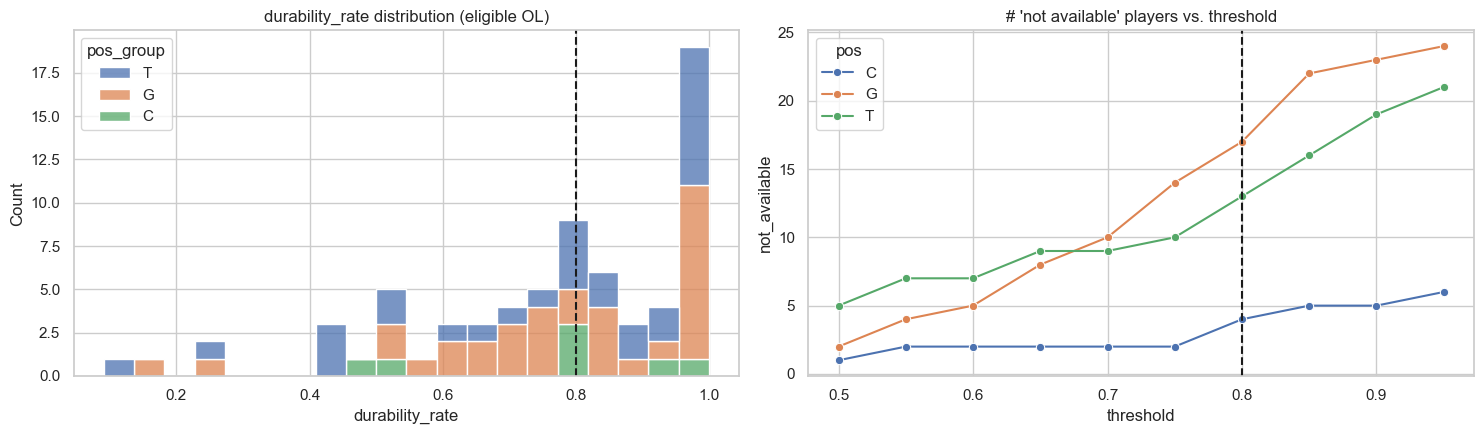

group,available,not available,All
draft class,,,
2023,13,10,23
2024,11,14,25
2025,13,9,22
All,37,33,70


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
el = ol[ol["eligible"]]
sns.histplot(el, x=RATE, hue="pos_group", multiple="stack", bins=20, ax=axes[0])
axes[0].axvline(THRESHOLD, color="k", ls="--"); axes[0].set_title(f"{RATE} distribution (eligible OL)")

# Threshold sensitivity: how group sizes move as the cut changes
sweep = pd.DataFrame([{"threshold": t, "pos": p, "not_available": (d[RATE] < t).sum()}
                      for t in np.arange(0.5, 1.0, 0.05) for p, d in el.groupby("pos_group")])
sns.lineplot(data=sweep, x="threshold", y="not_available", hue="pos", marker="o", ax=axes[1])
axes[1].axvline(THRESHOLD, color="k", ls="--"); axes[1].set_title("# 'not available' players vs. threshold")
plt.tight_layout(); plt.show()

display(pd.crosstab(el[DRAFT_YR], el["group"], margins=True, normalize=False).rename_axis(index="draft class"))

In [7]:
LOWER_IS_BETTER = {"forty", "ten_yd_split", "twenty_yd_split", "three_cone", "short_shuttle",
                   "duration_s", "time_to_peak_speed", "time_to_2yd", "time_to_first_move", "age_at_combine",
                   "draft_pick", "draft_round", PICK or "", ROUND or ""}

def zscore_within(df, col, by):
    g = df.groupby(by, dropna=False)[col]
    return (df[col] - g.transform("mean")) / g.transform("std")

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.nan

def boot_d(a, b, n=N_BOOT):
    a, b = np.asarray(a), np.asarray(b)
    ds = [cohens_d(pd.Series(RNG.choice(a, len(a))), pd.Series(RNG.choice(b, len(b)))) for _ in range(n)]
    return np.nanpercentile(ds, [2.5, 97.5])

def compare(df, cols, z_by=("pos_group",), label=None, lower_better=LOWER_IS_BETTER):
    d0 = df[df["group"].isin(["available", "not available"])].copy()
    rows = []
    for c in cols:
        if c not in d0 or not pd.api.types.is_numeric_dtype(d0[c]): continue
        z = zscore_within(d0, c, list(z_by))
        a = z[d0["group"] == "available"].dropna(); b = z[d0["group"] == "not available"].dropna()
        ra = d0.loc[a.index, c]; rb = d0.loc[b.index, c]
        row = {"metric": c, "n_avail": len(a), "n_not": len(b),
               "mean_avail": ra.mean(), "mean_not": rb.mean(),
               "median_avail": ra.median(), "median_not": rb.median()}
        if len(a) >= MIN_N_GROUP and len(b) >= MIN_N_GROUP and a.std() > 0:
            d = cohens_d(a, b); lo, hi = boot_d(a, b)
            sign = -1 if c in lower_better else 1
            row.update(d=d, ci_lo=lo, ci_hi=hi, mw_p=stats.mannwhitneyu(a, b).pvalue,
                       favors=("available" if d * sign > 0 else "not available"),
                       ci_excludes_0=(lo > 0) or (hi < 0))
        rows.append(row)
    out = pd.DataFrame(rows)
    if label: out.insert(0, "set", label)
    return out.sort_values("d", key=lambda s: s.abs(), ascending=False, na_position="last") if "d" in out else out

def forest(res, title, ax=None):
    r = res.dropna(subset=["d"]).sort_values("d")
    if r.empty: print("nothing to plot"); return
    ax = ax or plt.subplots(figsize=(8, 0.35 * len(r) + 1.5))[1]
    cols = np.where(r["ci_excludes_0"], "#C44E52", "#7F7F7F")
    ax.errorbar(r["d"], range(len(r)), xerr=[r["d"] - r["ci_lo"], r["ci_hi"] - r["d"]], fmt="none", ecolor=cols, alpha=.7)
    ax.scatter(r["d"], range(len(r)), c=cols, zorder=3)
    lbl = r["metric"] + "  (n=" + r["n_avail"].astype(str) + "/" + r["n_not"].astype(str) + ")"
    ax.set_yticks(range(len(r))); ax.set_yticklabels(lbl, fontsize=9)
    ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Cohen's d (available − not available), within-position z")
    ax.set_title(title + "\n(red = 95% CI excludes 0)")
    return ax

def group_box(df, cols, by="pos_group", ncols=4):
    d0 = df[df["group"].isin(["available", "not available"])]
    cols = [c for c in cols if c in d0 and d0[c].notna().sum() > 5]
    rows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(rows, ncols, figsize=(4.3 * ncols, 3.4 * rows), squeeze=False)
    for ax, c in zip(axes.flat, cols):
        sns.boxplot(data=d0, x=by, y=c, hue="group", palette=GROUP_COLORS, order=["C", "G", "T"],
                    ax=ax, showfliers=False)
        sns.stripplot(data=d0, x=by, y=c, hue="group", palette=GROUP_COLORS, order=["C", "G", "T"],
                      dodge=True, ax=ax, size=3, alpha=.6, legend=False)
        ax.set_title(c); ax.set_xlabel("")
        if ax is not axes.flat[0] and ax.get_legend(): ax.get_legend().remove()
    for ax in axes.flat[len(cols):]: ax.axis("off")
    plt.tight_layout(); plt.show()

,set,metric,n_avail,n_not,mean_avail,mean_not,median_avail,median_not,d,ci_lo,ci_hi,mw_p,favors,ci_excludes_0
13,combine tests,ngs_college_production_score,37,33,73.703,70.485,74.000,69.000,0.371,-0.091,0.867,0.111,available,False
11,combine tests,bench_reps,17,15,27.706,26.400,29.000,26.000,0.366,-0.337,1.190,0.227,available,False
3,combine tests,arm_length,37,33,33.588,33.265,33.500,33.250,0.242,-0.198,0.736,0.276,available,False
6,combine tests,forty,28,28,5.119,5.161,5.115,5.190,-0.236,-0.777,0.286,0.346,available,False
12,combine tests,ngs_athleticism_score,37,33,78.514,77.515,80.000,79.000,0.147,-0.351,0.612,0.778,available,False
4,combine tests,hand_size,37,33,10.027,10.102,10.000,10.125,-0.136,-0.626,0.342,0.343,not available,False
10,combine tests,short_shuttle,18,18,4.649,4.627,4.660,4.650,0.120,-0.538,0.789,0.849,not available,False
7,combine tests,vertical,33,27,30.591,30.315,30.000,29.500,0.097,-0.400,0.623,0.749,available,False
9,combine tests,three_cone,14,17,7.636,7.628,7.645,7.690,-0.075,-0.881,0.688,0.921,available,False
0,combine tests,combine_height,37,33,77.064,76.981,77.125,76.750,-0.024,-0.523,0.475,0.995,not available,False


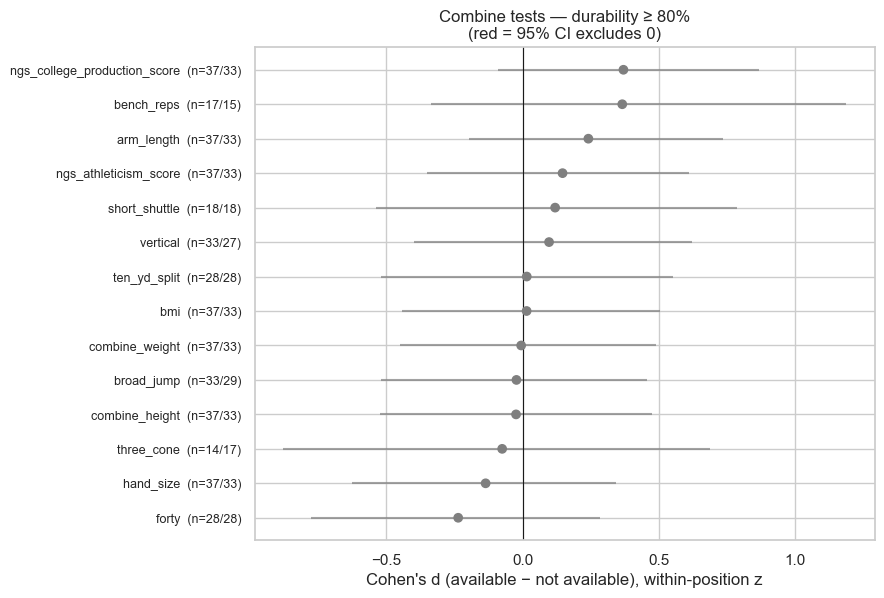

In [8]:
TESTS = [c for c in ["combine_height", "combine_weight", "bmi", "arm_length", "hand_size", "wingspan",
                     "ten_yd_split", "forty", "vertical", "broad_jump", "three_cone", "short_shuttle",
                     "bench_reps"] if c in ol]
GRADES = [c for c in ol if any(k in c.lower() for k in ["grade", "athleticism", "production_score", "ngs_score"])
          and pd.api.types.is_numeric_dtype(ol[c])]
res_tests = compare(ol, TESTS + GRADES, label="combine tests")
display(res_tests.round(3))
forest(res_tests, f"Combine tests — {AVAIL_DEF} ≥ {THRESHOLD:.0%}"); plt.show()

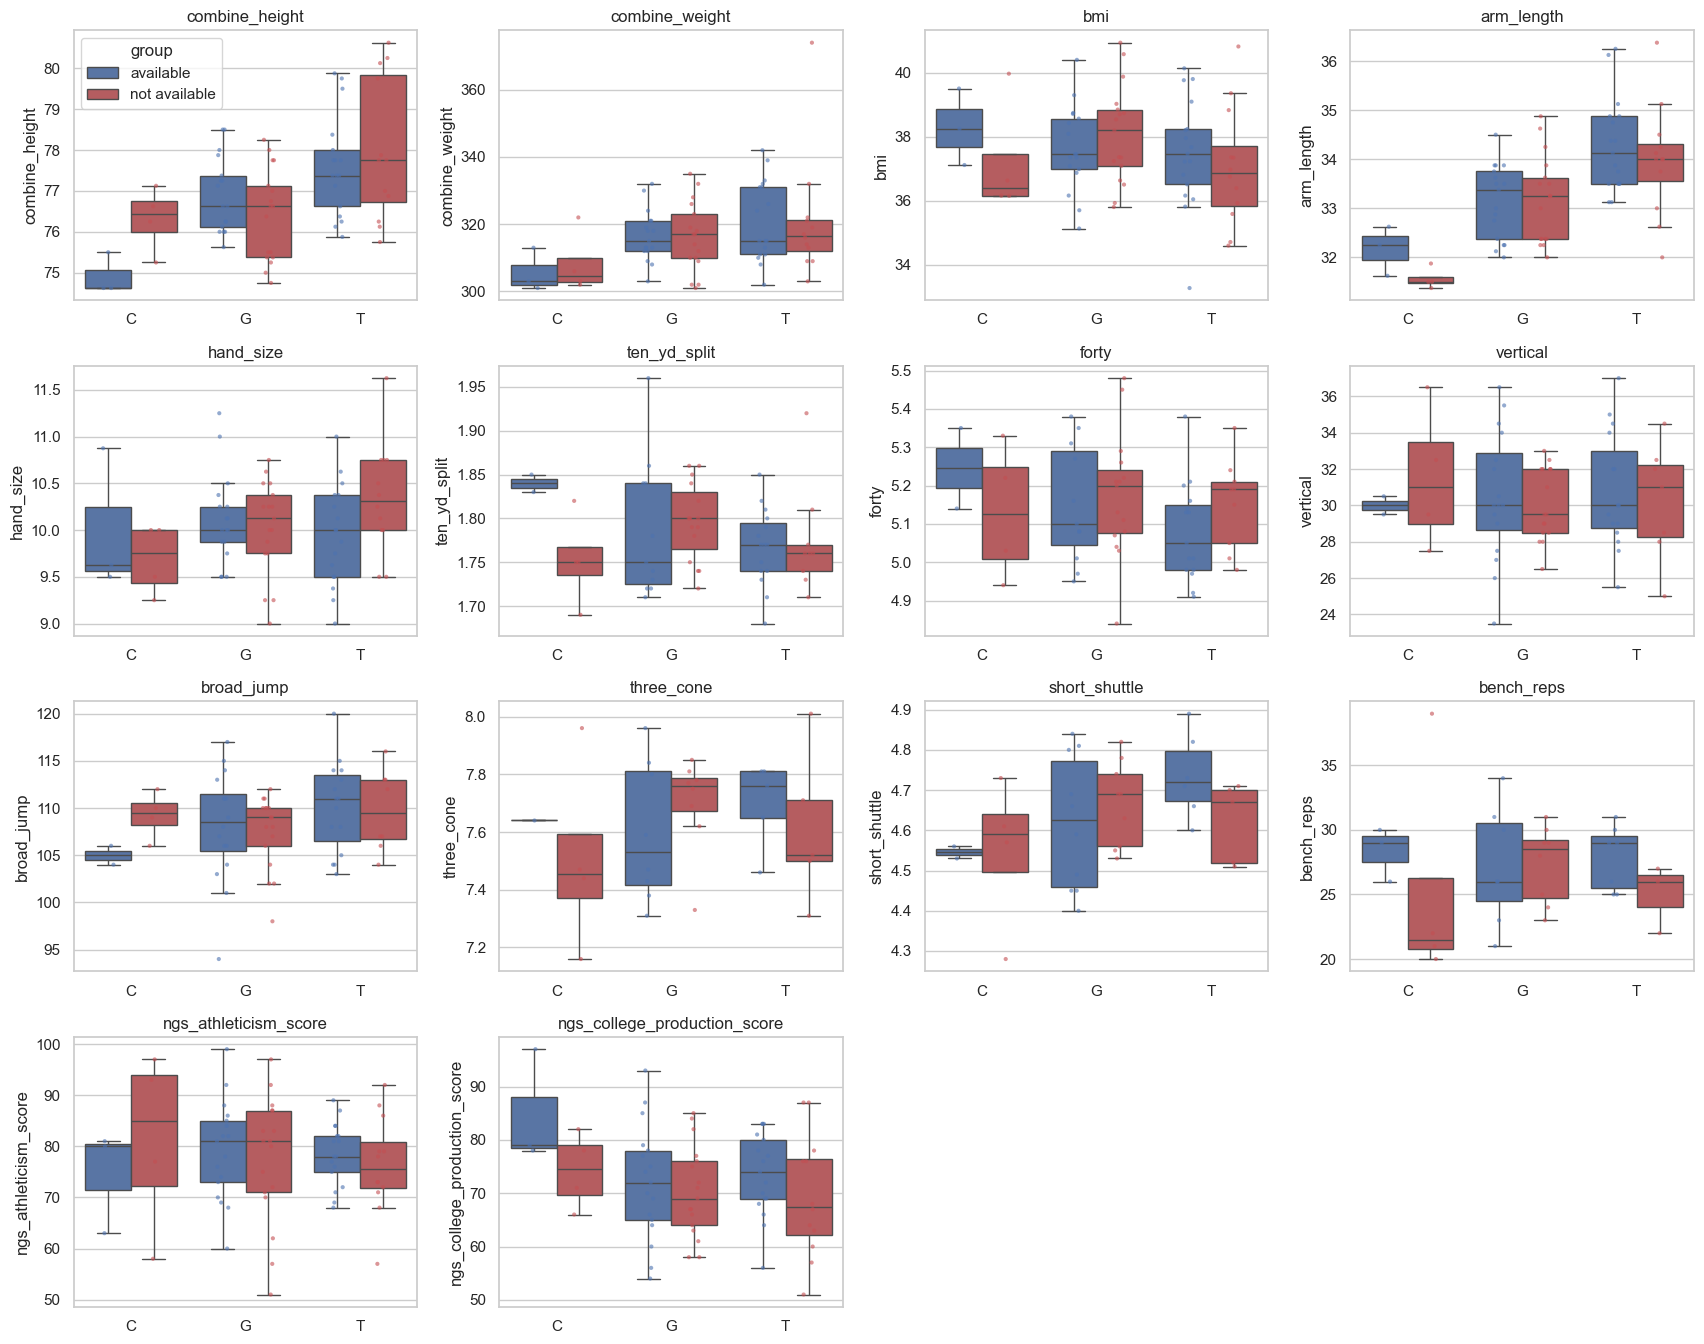

In [9]:
group_box(ol, TESTS + GRADES)

group sizes: {'available': 37, 'not available': 33}


,available,not available,diff (avail − not),fisher_p
skipped_forty,0.243,0.152,0.092,0.384
skipped_ten_yd_split,0.243,0.152,0.092,0.384
skipped_vertical,0.108,0.182,-0.074,0.499
skipped_broad_jump,0.108,0.121,-0.013,1.000
skipped_three_cone,0.622,0.485,0.137,0.336
skipped_short_shuttle,0.514,0.455,0.059,0.641
skipped_bench_reps,0.541,0.545,-0.005,1.000
n_skipped,2.378,2.091,0.287,NaN


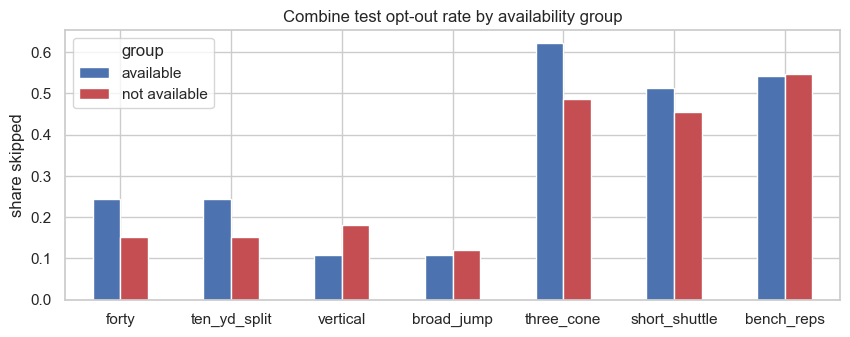

In [10]:
skip_tests = [c for c in ["forty", "ten_yd_split", "vertical", "broad_jump", "three_cone", "short_shuttle", "bench_reps"] if c in ol]
d0 = ol[ol["group"].isin(["available", "not available"])].copy()
for c in skip_tests: d0[f"skipped_{c}"] = d0[c].isna()
d0["n_skipped"] = d0[[f"skipped_{c}" for c in skip_tests]].sum(axis=1)

rates = d0.groupby("group")[[f"skipped_{c}" for c in skip_tests] + ["n_skipped"]].mean().T
rates.columns.name = None
counts = d0.groupby("group").size()
rates["diff (avail − not)"] = rates.get("available", np.nan) - rates.get("not available", np.nan)
# Fisher exact test per test (2×2), descriptive only
rates["fisher_p"] = [stats.fisher_exact(pd.crosstab(d0["group"], d0[f"skipped_{c}"]).reindex(columns=[False, True], fill_value=0).values)[1]
                     if d0[f"skipped_{c}"].nunique() > 1 else np.nan for c in skip_tests] + [np.nan]
print("group sizes:", counts.to_dict()); display(rates.round(3))

fig, ax = plt.subplots(figsize=(10, 3.5))
(d0.groupby(["group"])[[f"skipped_{c}" for c in skip_tests]].mean().T
   .rename(index=lambda s: s.replace("skipped_", ""))
   .plot.bar(ax=ax, color=[GROUP_COLORS.get(g) for g in sorted(d0["group"].unique())]))
ax.set_ylabel("share skipped"); ax.set_title("Combine test opt-out rate by availability group"); plt.xticks(rotation=0); plt.show()

In [ ]:
DRILL_FIXES = {"PASS_PRO-MIRROR_DRILL": "PASS_PRO_MIRROR_DRILL", "LINE": "LINE_DRILL",
               "OVER_SHOULDER_ADJUST": "OVER_THE_SHOULDER_ADJUST",
               "SPEED_OUT_LEFT": "SPEED_OUT_ROUTE_LEFT", "SPEED_OUT_RIGHT": "SPEED_OUT_ROUTE_RIGHT"}

ct = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
if "entity_type" in ct: ct = ct[ct["entity_type"] == "PLAYER"]
ct = ct[ct["nfl_id"].isin(ol["nfl_id"])].copy()
ct["drill_name"] = ct["drill_name"].replace(DRILL_FIXES)
ct["time"] = pd.to_datetime(ct["time"], errors="coerce")
ct = ct.sort_values(["event_id", "nfl_id", "time"])
print(f"OL tracking rows: {len(ct):,}, attempts: {ct.groupby(['event_id','nfl_id']).ngroups:,}")

MOVE_SPEED = 0.5
def rep_features(r):
    t = (r["time"] - r["time"].iloc[0]).dt.total_seconds().to_numpy() if r["time"].notna().all() else np.arange(len(r)) * 0.1
    x, y = r["x"].to_numpy(float), r["y"].to_numpy(float)
    dt = np.diff(t, prepend=np.nan); dt[dt <= 0] = np.nan
    step = np.hypot(np.diff(x, prepend=np.nan), np.diff(y, prepend=np.nan))
    v = step / dt
    s = r["s"].to_numpy(float) if "s" in r else v
    moving = np.where(np.nan_to_num(s) > MOVE_SPEED)[0]
    if len(moving) < 3: return None
    i0 = moving[0]
    t, x, y, s, step = t[i0:] - t[i0], x[i0:], y[i0:], s[i0:], np.nan_to_num(step[i0:])
    step[0] = 0
    acc = np.gradient(s, t) if len(t) > 2 and np.all(np.diff(t) > 0) else np.full_like(s, np.nan)
    disp = np.hypot(x - x[0], y - y[0])
    # main axis via PCA of the path, reversals = sign changes of velocity along it (ignoring tiny jitter)
    xy = np.c_[x - x.mean(), y - y.mean()]
    axis = np.linalg.svd(xy, full_matrices=False)[2][0] if len(xy) > 2 else np.array([1, 0])
    along = np.diff(xy @ axis)
    sig = np.sign(along[np.abs(along) > 0.02])
    return {"peak_speed": np.nanmax(s), "mean_speed": np.nanmean(s[s > MOVE_SPEED]) if (s > MOVE_SPEED).any() else np.nan,
            "peak_accel": np.nanmax(acc), "peak_decel": -np.nanmin(acc),
            "time_to_peak_speed": t[np.nanargmax(s)],
            "time_to_2yd": t[np.argmax(disp >= 2)] if (disp >= 2).any() else np.nan,
            "duration_s": t[-1], "path_dist": step.sum(),
            "n_reversals": int((np.diff(sig) != 0).sum()) if len(sig) > 1 else 0}

keys = ["event_id", "nfl_id", "drill_type", "drill_name"] + [c for c in ["draft_year", "attempt"] if c in ct]
feats = []
for k, r in ct.groupby(keys, sort=False):
    f = rep_features(r)
    if f: feats.append({**dict(zip(keys, k)), **f})
att = pd.DataFrame(feats)
FEATS = ["peak_speed", "mean_speed", "peak_accel", "peak_decel", "time_to_peak_speed",
         "time_to_2yd", "duration_s", "path_dist", "n_reversals"]
print(f"{len(att):,} attempts with features")
att.groupby("drill_name")[FEATS].median().round(2)

OL tracking rows: 79,100, attempts: 1,214
1,214 attempts with features


,peak_speed,mean_speed,peak_accel,peak_decel,time_to_peak_speed,time_to_2yd,duration_s,path_dist,n_reversals
drill_name,,,,,,,,,
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,7.41,2.93,5.42,5.20,14.8,2.3,15.10,44.29,5.0
FORTY_YARD_DASH,9.36,7.30,5.05,0.50,4.9,0.9,5.50,40.54,0.0
OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,7.95,5.11,3.51,-0.07,3.7,1.1,3.80,19.54,0.5
OL_PULL_DRILL_FOLD_BLOCK_RIGHT,7.08,4.13,3.47,0.03,3.3,1.3,3.30,13.65,1.0
OL_PULL_DRILL_LONG_PULL_RIGHT,6.98,4.05,4.07,3.20,4.6,1.0,4.70,19.75,1.0
PASS_PRO_MIRROR_DRILL,5.99,2.28,5.57,5.62,8.3,6.2,8.30,17.51,4.0
PASS_RUSH_DROP,6.07,2.67,3.22,1.90,4.2,1.5,4.20,11.04,0.0
SCREEN_DRILL,6.99,4.34,4.90,2.82,5.2,2.4,5.85,24.14,1.0
SHORT_SHUTTLE,5.47,2.95,7.02,7.23,5.0,1.0,5.10,15.03,2.0


In [12]:
# One row per player × drill (mean over attempts), joined to group labels
pdrill = att.groupby(["nfl_id", "drill_name"])[FEATS].mean().reset_index()
pdrill = pdrill.merge(ol[["nfl_id", "pos_group", "group", DRAFT_YR]], on="nfl_id")
pdrill_ok = pdrill[pdrill["group"].isin(["available", "not available"])]

n_by = pdrill_ok.groupby(["drill_name", "group"])["nfl_id"].nunique().unstack(fill_value=0)
keep = n_by[(n_by.min(axis=1) >= MIN_N_GROUP)].index.tolist()
print("Players per drill and group:"); display(n_by.sort_values("available", ascending=False))
print("Drills compared:", keep)

Players per drill and group:


group,available,not available
drill_name,,
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,37,33
PASS_PRO_MIRROR_DRILL,37,33
PASS_RUSH_DROP,37,32
OL_PULL_DRILL_FOLD_BLOCK_RIGHT,36,33
SCREEN_DRILL,36,32
OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,33,27
OL_PULL_DRILL_LONG_PULL_RIGHT,33,24
FORTY_YARD_DASH,28,28
SHORT_SHUTTLE,16,17


Drills compared: ['FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE', 'FORTY_YARD_DASH', 'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT', 'OL_PULL_DRILL_FOLD_BLOCK_RIGHT', 'OL_PULL_DRILL_LONG_PULL_RIGHT', 'PASS_PRO_MIRROR_DRILL', 'PASS_RUSH_DROP', 'SCREEN_DRILL', 'SHORT_SHUTTLE', 'THREE_CONE_DRILL']


C:\Users\bchm5\AppData\Local\Temp\ipykernel_17184\2687793165.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  annot = heat.round(2).astype(str) + np.where(star.fillna(False), "*", "")


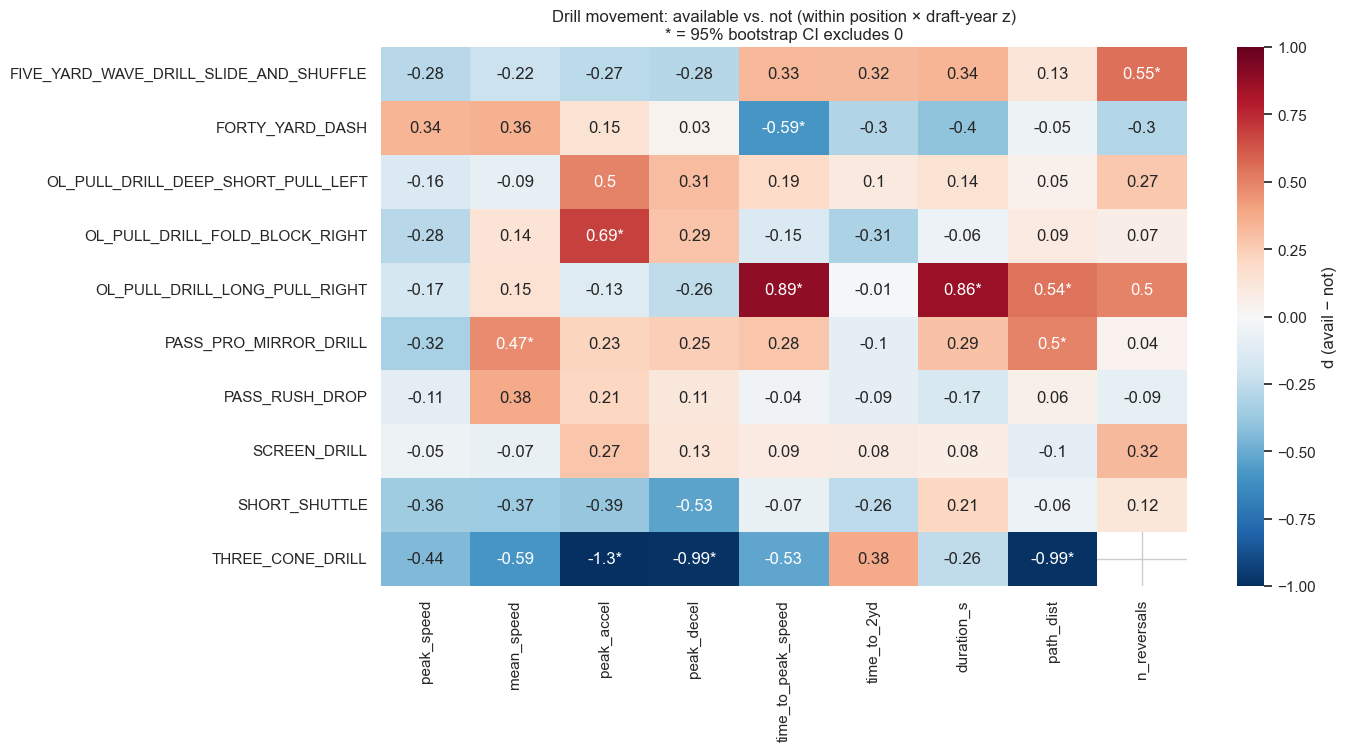

,set,metric,n_avail,n_not,mean_avail,mean_not,median_avail,median_not,d,ci_lo,ci_hi,mw_p,favors,ci_excludes_0
81,THREE_CONE_DRILL,peak_accel,12,14,5.530,5.497,5.401,5.953,-1.301,-2.772,-0.558,0.007,not available,True
82,THREE_CONE_DRILL,peak_decel,12,14,5.375,5.374,5.310,5.696,-0.987,-2.569,-0.180,0.017,not available,True
83,THREE_CONE_DRILL,path_dist,12,14,22.443,22.099,22.647,23.727,-0.986,-2.466,-0.191,0.033,not available,True
36,OL_PULL_DRILL_LONG_PULL_RIGHT,time_to_peak_speed,33,23,4.736,4.570,4.600,4.600,0.890,0.442,1.395,0.005,not available,True
37,OL_PULL_DRILL_LONG_PULL_RIGHT,duration_s,33,23,4.779,4.578,4.700,4.600,0.860,0.432,1.330,0.007,not available,True
27,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,peak_accel,36,33,3.678,3.345,3.513,3.417,0.687,0.248,1.195,0.006,available,True
84,THREE_CONE_DRILL,mean_speed,12,14,2.888,2.831,2.855,2.978,-0.593,-1.551,0.171,0.157,not available,False
9,FORTY_YARD_DASH,time_to_peak_speed,28,28,4.712,4.934,4.900,4.925,-0.592,-1.121,-0.089,0.050,available,True
0,FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,n_reversals,37,33,5.892,5.030,5.000,5.000,0.547,0.082,1.035,0.027,available,True
38,OL_PULL_DRILL_LONG_PULL_RIGHT,path_dist,33,23,19.646,18.884,19.750,18.202,0.542,0.033,1.083,0.046,available,True


In [13]:
drill_res = []
for dname in keep:
    sub = pdrill[pdrill["drill_name"] == dname]
    r = compare(sub, FEATS, z_by=("pos_group", DRAFT_YR), label=dname)
    drill_res.append(r)
drill_res = pd.concat(drill_res, ignore_index=True) if drill_res else pd.DataFrame()

if len(drill_res):
    heat = drill_res.pivot(index="set", columns="metric", values="d").reindex(columns=FEATS)
    star = drill_res.pivot(index="set", columns="metric", values="ci_excludes_0").reindex(columns=FEATS)
    annot = heat.round(2).astype(str) + np.where(star.fillna(False), "*", "")
    plt.figure(figsize=(13, 0.5 * len(heat) + 2))
    sns.heatmap(heat, annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar_kws={"label": "d (avail − not)"})
    plt.title("Drill movement: available vs. not (within position × draft-year z)\n* = 95% bootstrap CI excludes 0")
    plt.ylabel(""); plt.xlabel(""); plt.show()
    display(drill_res.dropna(subset=["d"]).sort_values("d", key=abs, ascending=False).head(15).round(3))

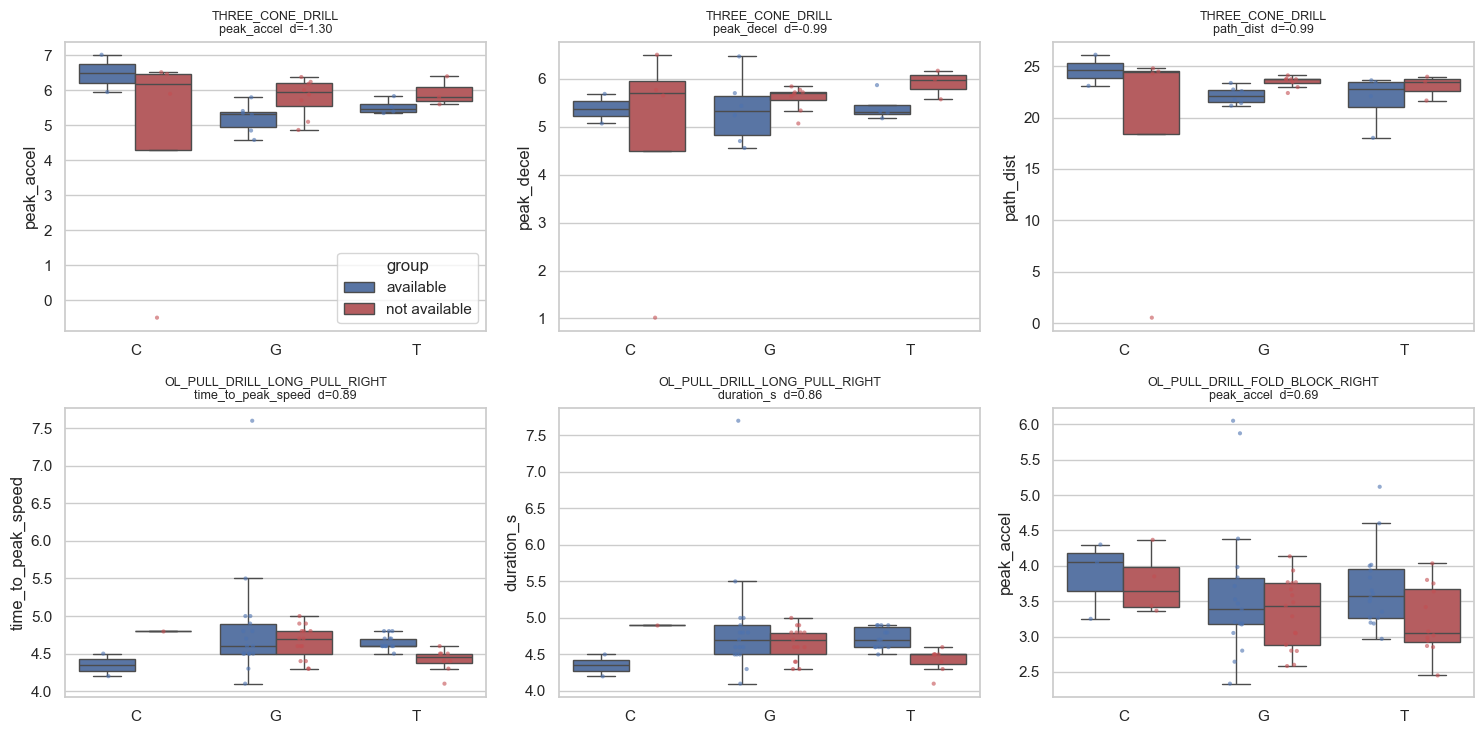

In [14]:
# Closer look: distributions for the 6 biggest drill × feature gaps
top = drill_res.dropna(subset=["d"]).sort_values("d", key=abs, ascending=False).head(6) if len(drill_res) else []
if len(top):
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
    for ax, (_, row) in zip(axes.flat, top.iterrows()):
        sub = pdrill_ok[pdrill_ok["drill_name"] == row["set"]]
        sns.boxplot(data=sub, x="pos_group", y=row["metric"], hue="group", palette=GROUP_COLORS,
                    order=["C", "G", "T"], showfliers=False, ax=ax)
        sns.stripplot(data=sub, x="pos_group", y=row["metric"], hue="group", palette=GROUP_COLORS,
                      order=["C", "G", "T"], dodge=True, size=3, alpha=.6, legend=False, ax=ax)
        ax.set_title(f"{row['set']}\n{row['metric']}  d={row['d']:.2f}", fontsize=9); ax.set_xlabel("")
        if ax is not axes.flat[0] and ax.get_legend(): ax.get_legend().remove()
    plt.tight_layout(); plt.show()

In [15]:
# Did the two groups even run the same drills? (Drill participation is itself a signal)
part = pdrill.groupby(["nfl_id"])["drill_name"].nunique().rename("n_tracked_drills")
d0 = ol.merge(part, left_on="nfl_id", right_index=True, how="left").fillna({"n_tracked_drills": 0})
d0 = d0[d0["group"].isin(["available", "not available"])]
display(d0.groupby("group")["n_tracked_drills"].describe().round(2))
display((pd.crosstab(pdrill_ok["drill_name"], pdrill_ok["group"]) / d0.groupby("group").size()).round(2)
          .rename(columns=lambda c: f"share of {c} who ran it"))

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
available,37.0,8.24,1.36,5.0,7.0,8.0,9.0,10.0
not available,33.0,8.30,1.26,6.0,7.0,8.0,9.0,10.0


group,share of available who ran it,share of not available who ran it
drill_name,,
FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE,1.00,1.00
FORTY_YARD_DASH,0.76,0.85
OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT,0.89,0.82
OL_PULL_DRILL_FOLD_BLOCK_RIGHT,0.97,1.00
OL_PULL_DRILL_LONG_PULL_RIGHT,0.89,0.73
PASS_PRO_MIRROR_DRILL,1.00,1.00
PASS_RUSH_DROP,1.00,0.97
SCREEN_DRILL,0.97,0.97
SHORT_SHUTTLE,0.43,0.52


,set,metric,n_avail,n_not,mean_avail,mean_not,median_avail,median_not,d,ci_lo,ci_hi,mw_p,favors,ci_excludes_0
0,bio/draft,draft_round,37,29,2.432,3.552,2.000,3.000,-0.608,-1.152,-0.148,0.012,available,True
1,bio/draft,draft_overall_pick,37,29,65.189,105.241,57.000,95.000,-0.592,-1.157,-0.120,0.025,available,True
2,bio/draft,age_at_combine,37,33,22.255,22.750,21.906,22.784,-0.444,-0.996,0.028,0.056,available,False
3,bio/draft,draft_year,37,33,2024.000,2023.970,2024.000,2024.000,-0.012,-0.481,0.468,0.896,not available,False


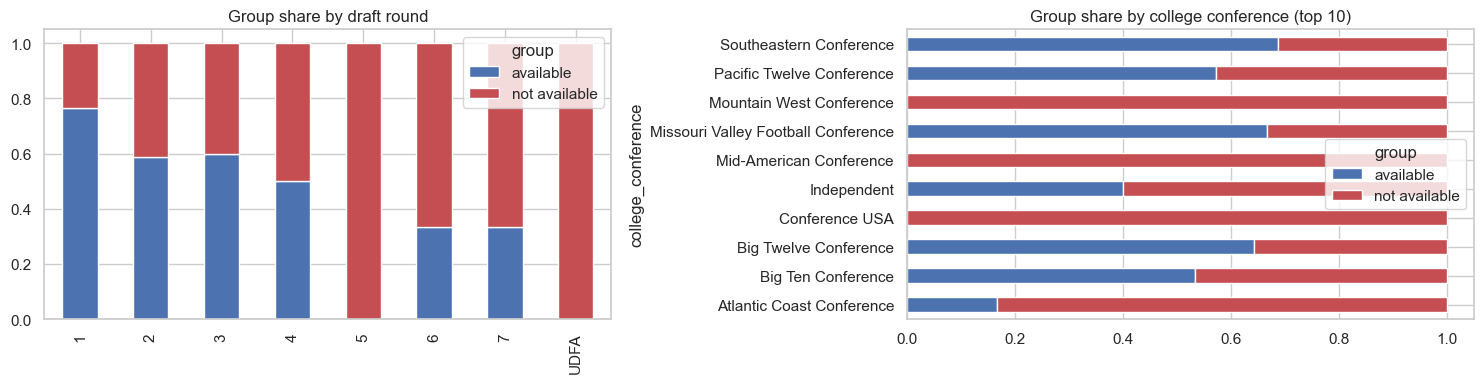

In [16]:
BIO = [c for c in [ROUND, PICK, "age_at_combine", DRAFT_YR] if c and c in ol]
res_bio = compare(ol, BIO, label="bio/draft")
display(res_bio.round(3))

d0 = ol[ol["group"].isin(["available", "not available"])].copy()
d0["round_label"] = d0[ROUND].fillna(0).astype(int).replace(0, "UDFA").astype(str) if ROUND else "?"
fig, axes = plt.subplots(1, 2 if CONF else 1, figsize=(15, 4), squeeze=False)
(pd.crosstab(d0["round_label"], d0["group"], normalize="index")
   .reindex([str(i) for i in range(1, 8)] + ["UDFA"]).dropna(how="all")
   .plot.bar(stacked=True, color=GROUP_COLORS, ax=axes[0, 0]))
axes[0, 0].set_title("Group share by draft round"); axes[0, 0].set_xlabel("")
if CONF:
    top_conf = d0[CONF].value_counts().head(10).index
    (pd.crosstab(d0.loc[d0[CONF].isin(top_conf), CONF], d0["group"], normalize="index")
       .plot.barh(stacked=True, color=GROUP_COLORS, ax=axes[0, 1]))
    axes[0, 1].set_title("Group share by college conference (top 10)")
plt.tight_layout(); plt.show()

Pass-pro rates use players with ≥100 pass blocks.


,set,metric,n_avail,n_not,mean_avail,mean_not,median_avail,median_not,d,ci_lo,ci_hi,mw_p,favors,ci_excludes_0
9,NFL outcomes,career_games_started_per_season,37,33,12.230,6.505,15.000,6.667,1.133,0.635,1.811,0.000,available,True
5,NFL outcomes,career_offensive_snaps_per_season,37,33,777.838,440.545,961.000,455.333,1.087,0.583,1.760,0.000,available,True
4,NFL outcomes,pass_blocks,37,33,849.973,507.545,632.000,446.000,0.750,0.308,1.256,0.005,available,True
8,NFL outcomes,career_games_active_per_season,37,33,15.919,13.838,17.000,14.000,0.719,0.235,1.293,0.003,available,True
7,NFL outcomes,career_special_teams_snaps_per_season,37,33,53.887,42.237,57.000,45.500,0.491,0.037,1.059,0.015,available,True
12,NFL outcomes,pro_bowl_original_ballot_per_season,17,12,0.000,0.042,0.000,0.000,-0.452,-0.866,0.000,0.263,not available,False
0,NFL outcomes,pressure_rate,36,30,0.088,0.091,0.087,0.085,-0.318,-0.829,0.203,0.312,available,False
11,NFL outcomes,ap_all_pro_2nd_team_per_season,17,12,0.020,0.000,0.000,0.000,0.315,0.000,0.583,0.441,available,False
3,NFL outcomes,mean_time_to_pressure,36,30,3.017,2.957,3.011,2.876,0.264,-0.246,0.826,0.214,available,False
2,NFL outcomes,mean_peak_pressure_prob,36,30,0.291,0.286,0.295,0.279,-0.119,-0.625,0.372,0.657,available,False


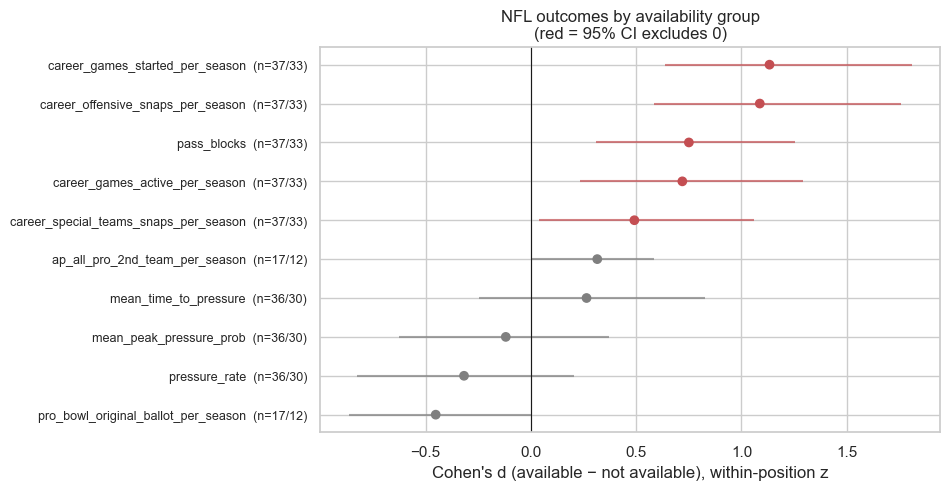

In [ ]:
PF = pick(ol_pp, ["pressure_allowed"])
SF = pick(ol_pp, ["sack_allowed"])
PK = pick(ol_pp, ["peak_pressure_probability_allowed"])
TTP = pick(ol_pp, ["time_to_pressure_allowed"])

pb = ol_pp[ol_pp[PF].notna()].copy() if PF else ol_pp.iloc[0:0].copy()

for c in [PF, SF]:
    if c: pb[c] = to_bool(pb[c])

agg = {"pass_blocks": ("play_id", "size")}

if PF: agg["pressure_rate"] = (PF, "mean")
if SF: agg["sack_rate"] = (SF, "mean")
if PK: agg["mean_peak_pressure_prob"] = (PK, "mean")
if TTP: agg["mean_time_to_pressure"] = (TTP, "mean")

ppro = pb.groupby("nfl_id").agg(**agg)
MIN_BLOCKS = 100
ppro.loc[ppro["pass_blocks"] < MIN_BLOCKS, [c for c in ppro if c != "pass_blocks"]] = np.nan

OUT_CAREER = [c for c in career.columns if c != "nfl_id" and pd.api.types.is_numeric_dtype(career[c])]
ol2 = ol.drop(columns=[c for c in ppro if c in ol]).merge(ppro, left_on="nfl_id", right_index=True, how="left")
ol2["seasons_available"] = LAST_SEASON - ol2[DRAFT_YR] + 1
for c in OUT_CAREER:
    if c in ol2: ol2[f"{c}_per_season"] = ol2[c] / ol2["seasons_available"]

OUTS = [c for c in ["pressure_rate", "sack_rate", "mean_peak_pressure_prob", "mean_time_to_pressure", "pass_blocks"] if c in ol2] \
     + [f"{c}_per_season" for c in OUT_CAREER if f"{c}_per_season" in ol2]
lower_out = LOWER_IS_BETTER | {"pressure_rate", "sack_rate", "mean_peak_pressure_prob"}
res_out = compare(ol2, OUTS, label="NFL outcomes", lower_better=lower_out)

print(f"Pass-pro rates use players with ≥{MIN_BLOCKS} pass blocks.")
display(res_out.round(3))
forest(res_out, "NFL outcomes by availability group"); plt.show()

Comparisons with enough players, by position: {'G': 105, 'T': 96}


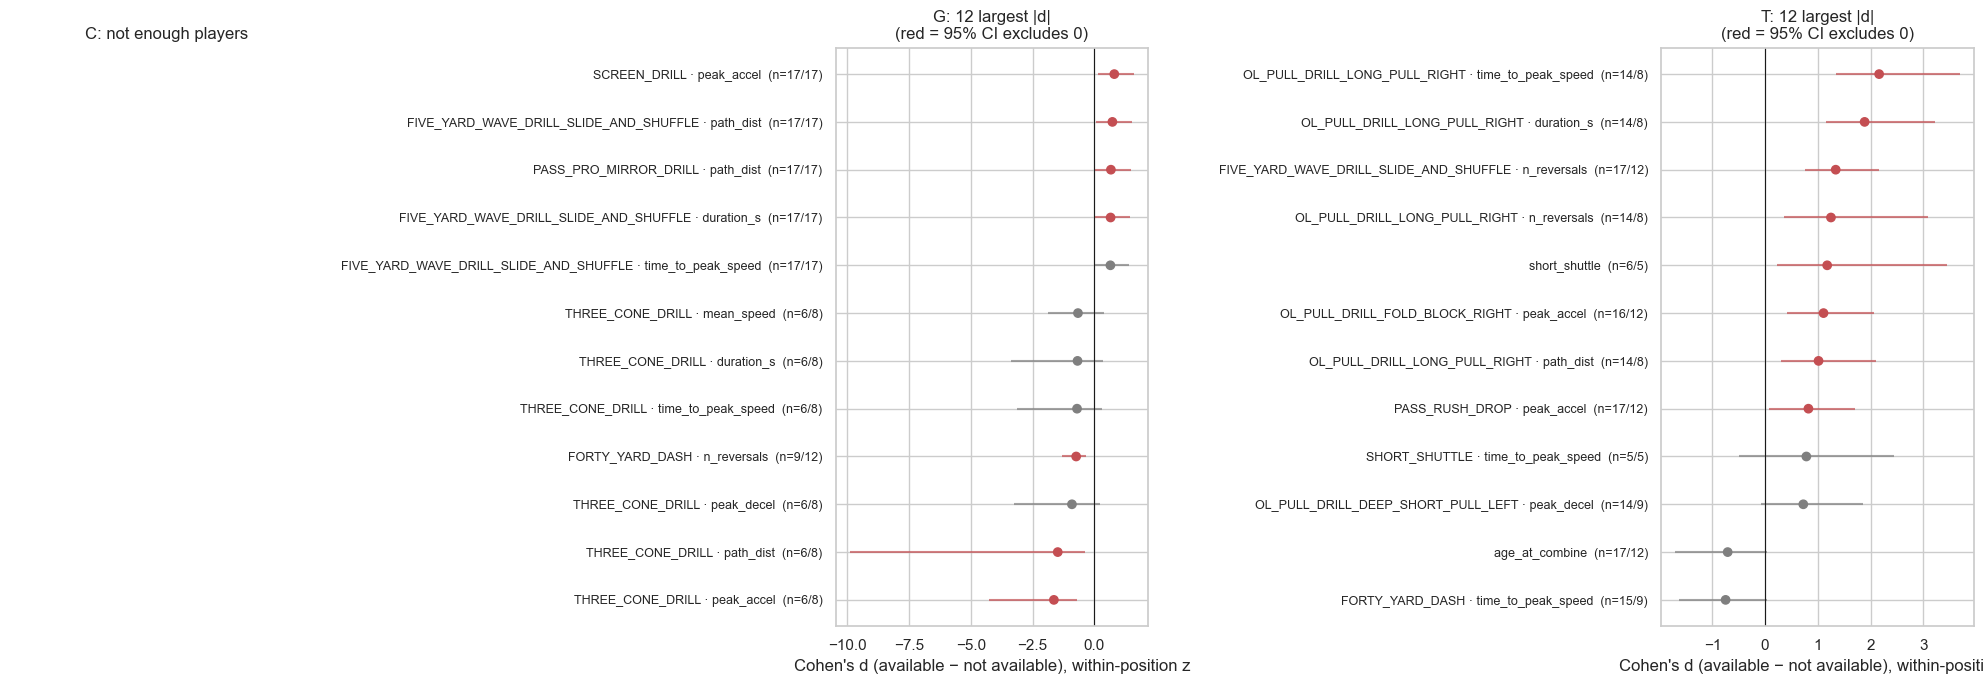

In [18]:
pos_res = []
for pos in ["C", "G", "T"]:
    sub = ol[ol["pos_group"] == pos]
    r = compare(sub, TESTS + GRADES + [c for c in BIO if c != DRAFT_YR], z_by=(DRAFT_YR,), label=pos)
    pos_res.append(r)
    for dname in keep:
        sd = pdrill[(pdrill["drill_name"] == dname) & (pdrill["pos_group"] == pos)]
        rr = compare(sd, FEATS, z_by=(DRAFT_YR,), label=pos)
        rr["metric"] = dname + " · " + rr["metric"]; pos_res.append(rr)
pos_res = pd.concat(pos_res, ignore_index=True)
print("Comparisons with enough players, by position:", pos_res.dropna(subset=["d"]).groupby("set").size().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, pos in zip(axes, ["C", "G", "T"]):
    r = pos_res[(pos_res["set"] == pos)].dropna(subset=["d"]).sort_values("d", key=abs, ascending=False).head(12)
    if len(r): forest(r, f"{pos}: 12 largest |d|", ax=ax)
    else: ax.set_title(f"{pos}: not enough players"); ax.axis("off")
plt.tight_layout(); plt.show()

## Summary table

In [19]:
allres = pd.concat([res_tests, res_bio, drill_res.assign(metric=lambda d: d["set"] + " · " + d["metric"]) if len(drill_res) else None,
                    res_out], ignore_index=True)
summ = (allres.dropna(subset=["d"])
              .assign(abs_d=lambda d: d["d"].abs())
              .sort_values("abs_d", ascending=False)
              [["set", "metric", "n_avail", "n_not", "d", "ci_lo", "ci_hi", "favors", "ci_excludes_0", "mw_p"]])
print(f"{AVAIL_DEF} ≥ {THRESHOLD:.0%} | {len(summ)} comparisons | "
      f"{int(summ['ci_excludes_0'].sum())} with CI excluding 0 (≈{0.05*len(summ):.1f} expected by chance alone)")
summ.head(25).round(3)

durability ≥ 80% | 117 comparisons | 1 with CI excluding 0 (≈5.9 expected by chance alone)


,set,metric,n_avail,n_not,d,ci_lo,ci_hi,favors,ci_excludes_0,mw_p
99,THREE_CONE_DRILL,THREE_CONE_DRILL · peak_accel,12,14,-1.301,-2.772,-0.558,not available,True,0.007
108,NFL outcomes,career_games_started_per_season,37,33,1.133,0.635,1.811,available,True,0.000
109,NFL outcomes,career_offensive_snaps_per_season,37,33,1.087,0.583,1.760,available,True,0.000
100,THREE_CONE_DRILL,THREE_CONE_DRILL · peak_decel,12,14,-0.987,-2.569,-0.180,not available,True,0.017
101,THREE_CONE_DRILL,THREE_CONE_DRILL · path_dist,12,14,-0.986,-2.466,-0.191,not available,True,0.033
54,OL_PULL_DRILL_LONG_PULL_RIGHT,OL_PULL_DRILL_LONG_PULL_RIGHT · time_to_peak_s...,33,23,0.890,0.442,1.395,not available,True,0.005
55,OL_PULL_DRILL_LONG_PULL_RIGHT,OL_PULL_DRILL_LONG_PULL_RIGHT · duration_s,33,23,0.860,0.432,1.330,not available,True,0.007
110,NFL outcomes,pass_blocks,37,33,0.750,0.308,1.256,available,True,0.005
111,NFL outcomes,career_games_active_per_season,37,33,0.719,0.235,1.293,available,True,0.003
45,OL_PULL_DRILL_FOLD_BLOCK_RIGHT,OL_PULL_DRILL_FOLD_BLOCK_RIGHT · peak_accel,36,33,0.687,0.248,1.195,available,True,0.006


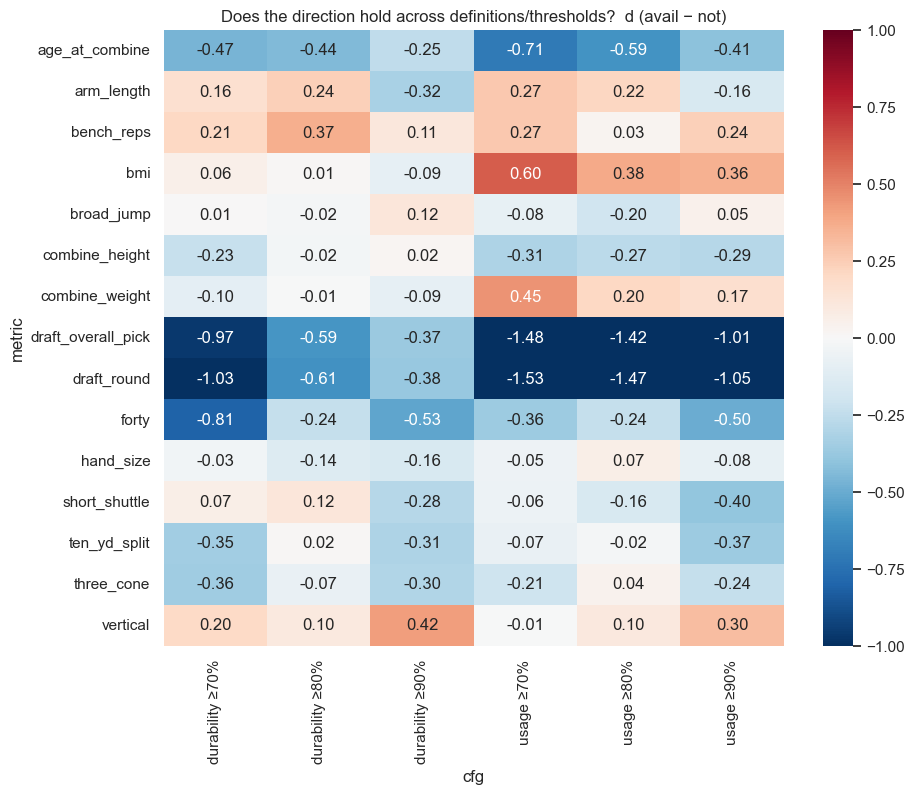

In [20]:
# Robustness: rerun the headline Combine-test comparison under both definitions and three thresholds
rob = []
for dfn, (rate, den) in {"durability": ("durability_rate", "dur_den"), "usage": ("usage_rate", "usage_den")}.items():
    for thr in [0.7, 0.8, 0.9]:
        tmp = ol.copy()
        elig = tmp[den].fillna(0) >= MIN_GAMES_DEN
        tmp["group"] = np.where(~elig, "excluded", np.where(tmp[rate] >= thr, "available", "not available"))
        r = compare(tmp, TESTS + [c for c in BIO if c != DRAFT_YR])
        if "d" in r: rob.append(r.assign(cfg=f"{dfn} ≥{thr:.0%}")[["cfg", "metric", "d"]])
if rob:
    rob = pd.concat(rob).pivot(index="metric", columns="cfg", values="d")
    plt.figure(figsize=(10, 0.4 * len(rob) + 2))
    sns.heatmap(rob, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
    plt.title("Does the direction hold across definitions/thresholds?  d (avail − not)"); plt.show()